# Lab 6: Frequency Domain
# Mohammad Buhamad
# 2240005142


In [7]:
# Load and resize image
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize
from numpy.fft import fft2, ifftshift, ifft2

image = data.camera()
image = resize(image, (256, 256))
M, N = image.shape

In [8]:
# Sobel filters
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])
sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

In [9]:
# Proper padding and centering of kernel in spatial domain
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    cy, cx = ph // 2, pw // 2
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel
    return fft2(ifftshift(padded))

In [10]:
# Compute FFT of image
F_image = fft2(image)

# FFT of centered Sobel filters
F_sobel_x = center_embed_kernel(sobel_x, (M, N))
F_sobel_y = center_embed_kernel(sobel_y, (M, N))

In [11]:
# Multiply in the frequency domain
F_x = F_image * F_sobel_x
F_y = F_image * F_sobel_y

# Inverse FFT to get spatial results
sobel_x_image = ifft2(F_x).real
sobel_y_image = ifft2(F_y).real
sobel_magnitude = np.sqrt(sobel_x_image**2 + sobel_y_image**2)

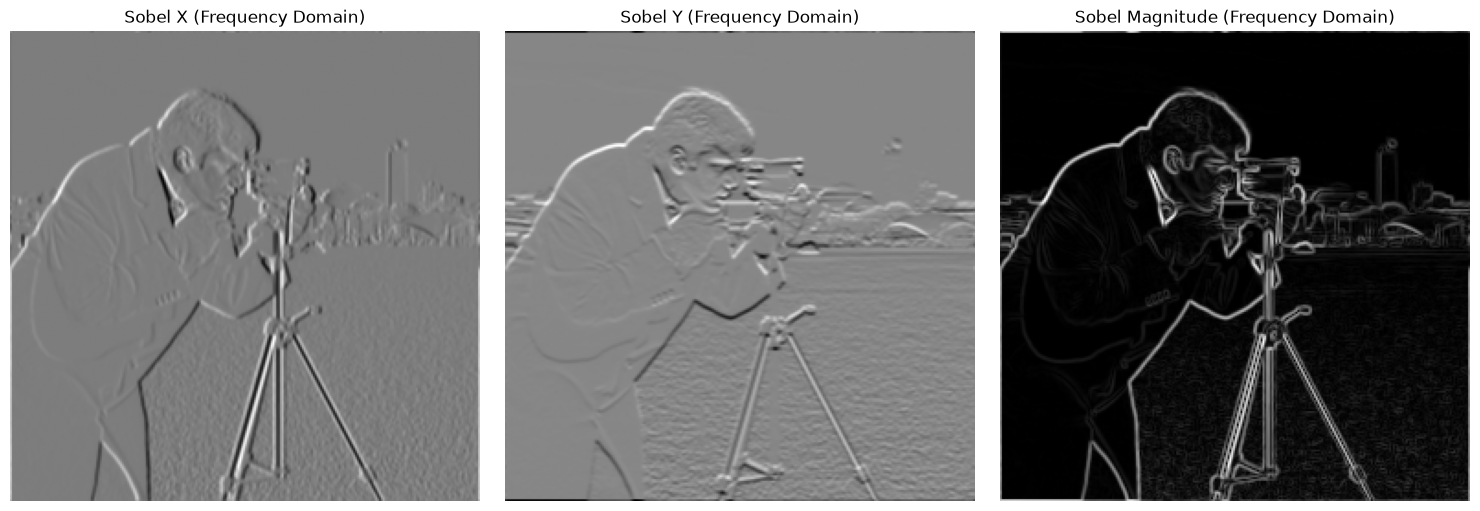

In [15]:
# Plot
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(sobel_x_image, cmap='gray')
plt.title('Sobel X (Frequency Domain)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(sobel_y_image, cmap='gray')
plt.title('Sobel Y (Frequency Domain)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(sobel_magnitude, cmap='gray')
plt.title('Sobel Magnitude (Frequency Domain)')
plt.axis('off')

plt.tight_layout()
plt.show()